### Task 2 Modeling 

In [31]:
import re
import math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

### Dataset preparation

In [13]:
df = pd.read_csv('..\Datasets\malicious_phish.csv')
print(f"Initial shape: {df.shape}")

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\filip\AppData\Local\Temp\ipykernel_11808\1186710678.py:1: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_csv('..\Datasets\malicious_phish.csv')


Initial shape: (651191, 2)


In [14]:
df.head()

,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [15]:
# 1. Detect and drop URLs that have conflicting labels
conflicting_urls = df.groupby('url')['type'].nunique()
conflicting_urls = conflicting_urls[conflicting_urls > 1].index
print(f"Conflicting URLs found: {len(conflicting_urls)}")

df = df[~df['url'].isin(conflicting_urls)].copy()

# 2. Drop duplicate URLs (keeping the first occurrence)
before_dedup = len(df)
df = df.drop_duplicates(subset=['url']).reset_index(drop=True)
print(f"Dropped {before_dedup - len(df):,} duplicate URLs. Cleaned rows: {len(df):,}")

Conflicting URLs found: 6
Dropped 10,066 duplicate URLs. Cleaned rows: 641,113


In [17]:
# Extract protocol into categorical and binary indicator features, then strip from the URL
def extract_protocol(url: str):
    lower = url.lower()
    if lower.startswith('https://'):
        return 'https', url[8:]
    elif lower.startswith('http://'):
        return 'http', url[7:]
    elif lower.startswith('ftp://'):
        return 'ftp', url[6:]
    return 'none', url

protocols, clean_urls = zip(*df['url'].map(extract_protocol))
df['protocol'] = protocols
df['clean_url'] = clean_urls

# Binary indicators for protocol
df['has_https'] = (df['protocol'] == 'https').astype(np.int8)
df['has_http'] = (df['protocol'] == 'http').astype(np.int8)
df['has_no_protocol'] = (df['protocol'] == 'none').astype(np.int8)

# Targets:
# 1. Multiclass target (4 classes)
y_multi = df['type']

# 2. Binary target (0: Benign, 1: Malicious)
y_binary = (df['type'] != 'benign').astype(int)

print("Multiclass distribution:\n", y_multi.value_counts())
print("\nBinary distribution:\n", y_binary.value_counts(normalize=True) * 100)


Multiclass distribution:
 type
benign        428074
defacement     95308
phishing       94086
malware        23645
Name: count, dtype: int64

Binary distribution:
 type
0    66.770445
1    33.229555
Name: proportion, dtype: float64


In [18]:
def shannon_entropy(string: str) -> float:
    if not string:
        return 0.0
    counts = Counter(string)
    ln = len(string)
    return -sum((count / ln) * math.log2(count / ln) for count in counts.values())

# Fast vectorized lexical extraction for ~640k rows
print("Extracting lexical features...")
df['url_len'] = df['clean_url'].str.len()
df['count_dot'] = df['clean_url'].str.count(r'\.')
df['count_hyphen'] = df['clean_url'].str.count('-')
df['count_slash'] = df['clean_url'].str.count('/')
df['count_question'] = df['clean_url'].str.count(r'\?')
df['count_equal'] = df['clean_url'].str.count('=')
df['count_at'] = df['clean_url'].str.count('@')
df['count_percent'] = df['clean_url'].str.count('%')
df['count_underscore'] = df['clean_url'].str.count('_')
df['count_digits'] = df['clean_url'].str.count(r'\d')
df['digit_ratio'] = df['count_digits'] / (df['url_len'] + 1e-6)

# Hostname vs Path lengths (splitting by first slash)
first_slash = df['clean_url'].str.find('/')
df['hostname_len'] = np.where(first_slash == -1, df['url_len'], first_slash)
df['path_len'] = np.where(first_slash == -1, 0, df['url_len'] - first_slash)

# Structural & security indicators
df['has_ip'] = df['clean_url'].str.contains(r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', regex=True).astype(np.int8)
df['has_suspicious_keyword'] = df['clean_url'].str.contains(
    r'login|verify|account|update|banking|secure|signin|ebayisapi|webscr|wallet|admin',
    case=False, regex=True
).astype(np.int8)

# Shannon entropy
df['entropy'] = [shannon_entropy(u) for u in df['clean_url']]

lexical_feature_cols = [
    'has_https', 'has_http', 'has_no_protocol',
    'url_len', 'hostname_len', 'path_len',
    'count_dot', 'count_hyphen', 'count_slash',
    'count_question', 'count_equal', 'count_at',
    'count_percent', 'count_underscore', 'count_digits',
    'digit_ratio', 'has_ip', 'has_suspicious_keyword', 'entropy'
]

print(f"Extracted {len(lexical_feature_cols)} lexical features successfully.")


Extracting lexical features...
Extracted 19 lexical features successfully.


In [19]:
df

,url,type,protocol,clean_url,has_https,has_http,has_no_protocol,url_len,count_dot,count_hyphen,...,count_at,count_percent,count_underscore,count_digits,digit_ratio,hostname_len,path_len,has_ip,has_suspicious_keyword,entropy
0,br-icloud.com.br,phishing,none,br-icloud.com.br,0,0,1,16,2,1,...,0,0,0,0,0.000000,16,0,0,0,3.375000
1,mp3raid.com/music/krizz_kaliko.html,benign,none,mp3raid.com/music/krizz_kaliko.html,0,0,1,35,2,0,...,0,0,1,1,0.028571,11,24,0,0,4.079143
2,bopsecrets.org/rexroth/cr/1.htm,benign,none,bopsecrets.org/rexroth/cr/1.htm,0,0,1,31,2,0,...,0,0,0,1,0.032258,14,17,0,0,3.708093
3,http://www.garage-pirenne.be/index.php?option=...,defacement,http,www.garage-pirenne.be/index.php?option=com_con...,0,1,0,81,3,1,...,0,0,2,7,0.086420,21,60,0,0,4.605955
4,http://adventure-nicaragua.net/index.php?optio...,defacement,http,adventure-nicaragua.net/index.php?option=com_m...,0,1,0,228,2,1,...,0,0,1,22,0.096491,23,205,0,0,5.470630
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641108,xbox360.ign.com/objects/850/850402.html,phishing,none,xbox360.ign.com/objects/850/850402.html,0,0,1,39,3,0,...,0,0,0,12,0.307692,15,24,0,0,4.355539
641109,games.teamxbox.com/xbox-360/1860/Dead-Space/,phishing,none,games.teamxbox.com/xbox-360/1860/Dead-Space/,0,0,1,44,2,2,...,0,0,0,7,0.159091,18,26,0,0,4.243300
641110,www.gamespot.com/xbox360/action/deadspace/,phishing,none,www.gamespot.com/xbox360/action/deadspace/,0,0,1,42,2,0,...,0,0,0,3,0.071429,16,26,0,0,4.147921
641111,en.wikipedia.org/wiki/Dead_Space_(video_game),phishing,none,en.wikipedia.org/wiki/Dead_Space_(video_game),0,0,1,45,2,0,...,0,0,3,0,0.000000,16,29,0,0,4.102313


### Data Splitting

In [20]:
# Stratifying by y_multi preserves proportions for BOTH multiclass and binary tasks
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)

# Split Targets
y_train_binary, y_test_binary = y_binary.iloc[train_idx], y_binary.iloc[test_idx]
y_train_multi, y_test_multi = y_multi.iloc[train_idx], y_multi.iloc[test_idx]

# Split Lexical Features
X_train_lex = df.iloc[train_idx][lexical_feature_cols].values
X_test_lex = df.iloc[test_idx][lexical_feature_cols].values

# Split Clean URL text for vectorization
text_train = df.iloc[train_idx]['clean_url']
text_test = df.iloc[test_idx]['clean_url']

print(f"Train samples: {len(train_idx):,} | Test samples: {len(test_idx):,}")


Train samples: 512,890 | Test samples: 128,223


In [27]:
y_train_multi.value_counts()

type
benign        342459
defacement     76246
phishing       75269
malware        18916
Name: count, dtype: int64

In [21]:
# Configurable vectorizer budget
TFIDF_MAX_FEATURES = 10000   # Adjust based on memory experimentation (e.g. 5000, 10000, 20000)
TFIDF_NGRAM_RANGE = (3, 5)   # Subword character n-grams

print(f"Fitting character TF-IDF (max_features={TFIDF_MAX_FEATURES}, ngrams={TFIDF_NGRAM_RANGE})...")
tfidf = TfidfVectorizer(
    analyzer='char',
    ngram_range=TFIDF_NGRAM_RANGE,
    max_features=TFIDF_MAX_FEATURES,
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(text_train)
X_test_tfidf = tfidf.transform(text_test)

# Scale numerical lexical features
scaler = StandardScaler()
X_train_lex_scaled = scaler.fit_transform(X_train_lex)
X_test_lex_scaled = scaler.transform(X_test_lex)

# Combine into sparse hybrid matrices
X_train_hybrid = hstack([csr_matrix(X_train_lex_scaled), X_train_tfidf], format='csr')
X_test_hybrid = hstack([csr_matrix(X_test_lex_scaled), X_test_tfidf], format='csr')

print(f"Final Hybrid Matrix Shape: {X_train_hybrid.shape}")


Fitting character TF-IDF (max_features=10000, ngrams=(3, 5))...
Final Hybrid Matrix Shape: (512890, 10019)


### Binary models

Training Binary Classifier...

--- Binary Classification Report ---
               precision    recall  f1-score   support

   Benign (0)       0.97      0.97      0.97     85615
Malicious (1)       0.94      0.95      0.94     42608

     accuracy                           0.96    128223
    macro avg       0.96      0.96      0.96    128223
 weighted avg       0.96      0.96      0.96    128223



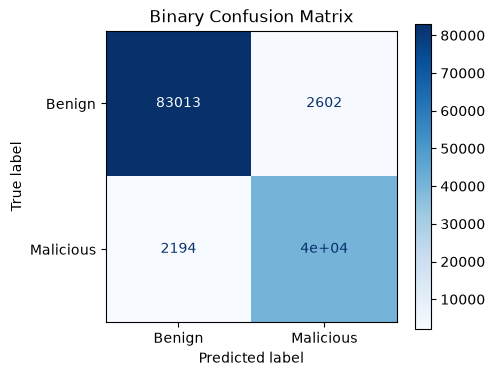

In [22]:
# SGDClassifier with log_loss trains fast logistic regression on large sparse matrices
binary_model = SGDClassifier(
    loss='log_loss',
    penalty='l2',
    alpha=1e-5,
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

print("Training Binary Classifier...")
binary_model.fit(X_train_hybrid, y_train_binary)

y_pred_binary = binary_model.predict(X_test_hybrid)

print("\n--- Binary Classification Report ---")
print(classification_report(y_test_binary, y_pred_binary, target_names=['Benign (0)', 'Malicious (1)']))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    display_labels=['Benign', 'Malicious'],
    cmap='Blues',
    ax=ax
)
plt.title("Binary Confusion Matrix")
plt.tight_layout()
plt.show()


### Multiclass models

Training Multiclass Classifier (4 classes)...

--- Multiclass Classification Report ---
              precision    recall  f1-score   support

      benign       0.97      0.97      0.97     85615
  defacement       0.96      0.99      0.97     19062
     malware       0.88      0.92      0.90      4729
    phishing       0.87      0.82      0.84     18817

    accuracy                           0.95    128223
   macro avg       0.92      0.92      0.92    128223
weighted avg       0.95      0.95      0.95    128223



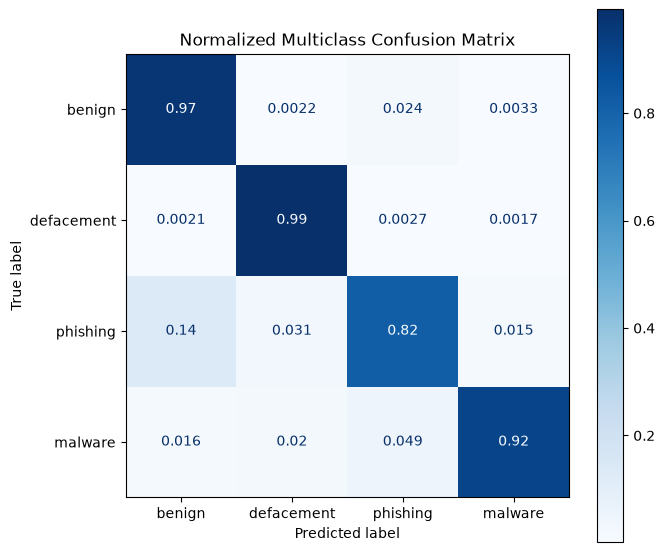

In [23]:
# Multiclass SGDClassifier (One-vs-Rest) with balanced class weights
multi_model = SGDClassifier(
    loss='log_loss',
    penalty='l2',
    alpha=1e-5,
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

print("Training Multiclass Classifier (4 classes)...")
multi_model.fit(X_train_hybrid, y_train_multi)

y_pred_multi = multi_model.predict(X_test_hybrid)

print("\n--- Multiclass Classification Report ---")
print(classification_report(y_test_multi, y_pred_multi))

# Multiclass Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    y_pred_multi,
    labels=['benign', 'defacement', 'phishing', 'malware'],
    cmap='Blues',
    normalize='true',
    ax=ax
)
plt.title("Normalized Multiclass Confusion Matrix")
plt.tight_layout()
plt.show()


In [32]:
# Multiclass SGDClassifier (One-vs-Rest) with balanced class weights

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train_multi)
y_test_encoded = le.transform(y_test_multi)
print("Class Mapping:", dict(zip(le.classes_, range(len(le.classes_)))))

# 2. Compute balanced sample weights to address class imbalance (~5% malware)
sample_weights = compute_sample_weight('balanced', y_train_encoded)


xgb_multi = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    tree_method='hist',           # Fast histogram algorithm for large matrices
    n_estimators=500,             # Number of boosting trees
    learning_rate=0.05,           # Conservative learning rate
    max_depth=8,                  # Good interaction depth
    min_child_weight=3,           # Guard against noise
    subsample=0.8,                # Row subsampling
    colsample_bytree=0.7,         # Feature subsampling for TF-IDF
    reg_alpha=0.1,                # L1 penalty
    reg_lambda=2.0,               # L2 penalty
    eval_metric='mlogloss',
    early_stopping_rounds=25,     # Auto-stop when validation loss plateaus
    random_state=42,
    n_jobs=-1
)


# 4. Train with validation set monitoring
print("Training XGBoost Multiclass Model...")
xgb_multi.fit(
    X_train_hybrid, 
    y_train_encoded,
    sample_weight=sample_weights,
    eval_set=[(X_test_hybrid, y_test_encoded)],
    verbose=50
)
# 5. Predict and Evaluate
y_pred_xgb_encoded = xgb_multi.predict(X_test_hybrid)
y_pred_xgb = le.inverse_transform(y_pred_xgb_encoded)
print("\n--- XGBoost Multiclass Report ---")
print(classification_report(y_test_multi, y_pred_xgb))
# Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    y_pred_xgb,
    labels=le.classes_,
    cmap='Greens',
    normalize='true',
    ax=ax
)
plt.title("Normalized XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()


Class Mapping: {'benign': 0, 'defacement': 1, 'malware': 2, 'phishing': 3}
Training XGBoost Multiclass Model...
[0]	validation_0-mlogloss:1.30853
[50]	validation_0-mlogloss:0.25756
[100]	validation_0-mlogloss:0.15114
[150]	validation_0-mlogloss:0.12418


KeyboardInterrupt: 